# Importancia das variaveis nos cinco modelos de predicao de obito por chikungunya

Este notebook calcula a importancia nativa de cada uma das 29 variaveis preditoras para os cinco algoritmos ja treinados na fase de modelagem: Regressao Logistica, Arvore de Decisao (CART), Random Forest, XGBoost e LightGBM.
Os cinco modelos usados aqui foram treinados depois da substituicao da unidade federada de residencia, `SG_UF`, 27 categorias, pela macrorregiao de residencia, `MACRORREGIAO`, 5 categorias, Norte, Nordeste, Centro-Oeste, Sudeste e Sul, no conjunto de preditores, uma mudanca de feature engineering feita para reduzir a cardinalidade dessa variavel geografica.
Este notebook recalcula do zero toda a importancia de variaveis com os cinco modelos retreinados nessa nova versao do conjunto de preditores, substituindo integralmente os resultados anteriores, que ainda usavam `SG_UF`.
Para os quatro modelos baseados em arvore, Arvore de Decisao, Random Forest, XGBoost e LightGBM, a importancia usada e a medida nativa de cada biblioteca: Gini, tambem chamada de MDI, para os dois primeiros, e ganho (gain) para XGBoost e LightGBM.
Para a Regressao Logistica, a importancia agregada por variavel e a soma dos valores absolutos dos coeficientes ajustados, somada entre todas as categorias quando a variavel e categorica e foi codificada em multiplas colunas por one hot encoding.
Nenhum modelo e retreinado neste notebook, os cinco pipelines usados sao exatamente os artefatos finais salvos em `output/modelos/`, ja ajustados em todo o periodo de treino de 2020 a 2023.
O notebook produz uma tabela ranqueada por modelo, uma tabela consolidada com o rank de cada variavel nos cinco modelos e o rank medio entre eles, a concordancia entre os cinco rankings por correlacao de Spearman, e uma tabela detalhada de razao de chances por categoria para a Regressao Logistica.
A comparacao destes resultados com a literatura cientifica sobre fatores de risco de obito por chikungunya nao e feita neste notebook, e fica para uma etapa posterior fora deste notebook.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessamento.py`, e cria os diretorios de saida usados ao longo do notebook.
As tabelas sao salvas em `analysis/results_importancia/`, sobrescrevendo os arquivos calculados antes da troca de `SG_UF` por `MACRORREGIAO`, e os graficos em `analysis/plots/importancia/`.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessamento

DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_MODELOS = PROJECT_ROOT / "output" / "modelos"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_importancia"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "importancia"

DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
NUMERO_VARIAVEIS_EM_DESTAQUE = 10

Carrega apenas os preditores do treino completo, ja construidos pelo pipeline de dados com a macrorregiao de residencia no lugar da antiga unidade federada, para obter a lista oficial das 29 variaveis originais e separar as numericas das categoricas.
Essa separacao segue exatamente a mesma convencao usada na fase de modelagem, em `utils/preprocessamento.py`, e nenhuma linha do treino e usada para ajustar nada neste notebook, apenas para nomear as colunas.

In [2]:
X_train = pd.read_parquet(DIRETORIO_FEATURES / "X_train.parquet")

COLUNAS_NUMERICAS = preprocessamento.COLUNAS_NUMERICAS
COLUNAS_CATEGORICAS = preprocessamento.obter_colunas_categoricas(X_train)
VARIAVEIS_ORIGINAIS = list(X_train.columns)

len(VARIAVEIS_ORIGINAIS), len(COLUNAS_NUMERICAS), len(COLUNAS_CATEGORICAS)

(29, 3, 26)

Carrega os cinco pipelines finais salvos pela fase de modelagem, cada um ja ajustado em todo o periodo de treino de 2020 a 2023 com a macrorregiao de residencia no conjunto de preditores.
Sao usados exclusivamente os artefatos originais, sem o sufixo `_calibrado`, ja que o reescalonador de calibracao e unidimensional e nao contem nenhuma informacao sobre a importancia das 29 variaveis preditoras.

In [3]:
modelos = {algoritmo: joblib.load(DIRETORIO_MODELOS / f"{algoritmo}.joblib") for algoritmo in ALGORITMOS}

{algoritmo: type(modelo.named_steps["classificador"]).__name__ for algoritmo, modelo in modelos.items()}

{'regressao_logistica': 'LogisticRegression',
 'arvore_decisao': 'DecisionTreeClassifier',
 'random_forest': 'RandomForestClassifier',
 'xgboost': 'XGBClassifier',
 'lightgbm': 'LGBMClassifier'}

Define duas funcoes auxiliares usadas pelos tres modelos que dependem do `ColumnTransformer` de codificacao one hot: Regressao Logistica, Arvore de Decisao e Random Forest.
A primeira funcao recupera a variavel original correspondente a uma coluna codificada: uma coluna numerica mantem o proprio nome apos o prefixo `numericas__`, enquanto uma coluna categorica tem o formato `categoricas__{variavel}_{categoria}`, identificado comparando esse sufixo com a lista das 26 variaveis categoricas, que agora inclui `MACRORREGIAO` no lugar de `SG_UF`.
A segunda funcao soma, para cada variavel original, os valores informados em todas as colunas codificadas que pertencem a ela, o que, para a Regressao Logistica, corresponde exatamente a soma dos valores absolutos dos coeficientes das categorias daquela variavel.

In [4]:
def mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador == "numericas":
        return nome_apos_prefixo

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            return variavel_categorica

    raise ValueError(f"Nenhuma variavel original encontrada para {nome_coluna_codificada}")


def agregar_importancia_one_hot_por_variavel(preprocessador, valores_por_coluna_codificada):
    nomes_colunas_codificadas = preprocessador.get_feature_names_out()
    importancia_por_variavel = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)

    for nome_coluna_codificada, valor in zip(nomes_colunas_codificadas, valores_por_coluna_codificada):
        variavel_original = mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada)
        importancia_por_variavel[variavel_original] += valor

    return importancia_por_variavel

## Regressao Logistica

A Regressao Logistica usa o `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e o valor absoluto do coeficiente ajustado pelo classificador, antes da agregacao pela funcao definida acima.
O sinal original dos coeficientes nao e descartado, e e reaproveitado mais adiante neste notebook na tabela de razao de chances por categoria, ja que a agregacao por soma de valores absolutos remove a direcao do efeito de cada categoria.

In [5]:
preprocessador_regressao_logistica = modelos["regressao_logistica"].named_steps["preprocessador"]
coeficientes_regressao_logistica = modelos["regressao_logistica"].named_steps["classificador"].coef_[0]

importancia_regressao_logistica = agregar_importancia_one_hot_por_variavel(
    preprocessador_regressao_logistica, np.abs(coeficientes_regressao_logistica)
)
importancia_regressao_logistica.sort_values(ascending=False).head(10)

CS_ESCOL_N      1.392231
MACRORREGIAO    0.931814
CS_RACA         0.888662
CS_GESTANT      0.846537
VOMITO          0.612549
RENAL           0.567048
IDADE_ANOS      0.549706
HEPATOPAT       0.494717
ARTRITE         0.395141
EXANTEMA        0.387200
dtype: float64

## Arvore de Decisao (CART)

A Arvore de Decisao usa o mesmo tipo de `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e a importancia de Gini, tambem chamada de MDI (mean decrease in impurity), calculada diretamente pelo `DecisionTreeClassifier` ja ajustado.

In [6]:
preprocessador_arvore_decisao = modelos["arvore_decisao"].named_steps["preprocessador"]
mdi_arvore_decisao = modelos["arvore_decisao"].named_steps["classificador"].feature_importances_

importancia_arvore_decisao = agregar_importancia_one_hot_por_variavel(
    preprocessador_arvore_decisao, mdi_arvore_decisao
)
importancia_arvore_decisao.sort_values(ascending=False).head(10)

IDADE_ANOS                   0.751570
TEMPO_SINTOMA_NOTIFICACAO    0.176661
DOR_RETRO                    0.038685
CS_RACA                      0.020514
CS_SEXO                      0.012570
MIALGIA                      0.000000
CEFALEIA                     0.000000
EXANTEMA                     0.000000
VOMITO                       0.000000
NAUSEA                       0.000000
dtype: float64

## Random Forest

O Random Forest usa o mesmo tipo de pre-processamento one hot da Arvore de Decisao, e a importancia bruta de cada coluna codificada e a media da importancia de Gini entre todas as arvores do ensemble, tambem calculada diretamente pelo `RandomForestClassifier` ja ajustado.

In [7]:
preprocessador_random_forest = modelos["random_forest"].named_steps["preprocessador"]
mdi_random_forest = modelos["random_forest"].named_steps["classificador"].feature_importances_

importancia_random_forest = agregar_importancia_one_hot_por_variavel(
    preprocessador_random_forest, mdi_random_forest
)
importancia_random_forest.sort_values(ascending=False).head(10)

IDADE_ANOS                   0.167516
TEMPO_SINTOMA_NOTIFICACAO    0.113185
SEMANA_EPI_SIN_PRI           0.082425
CS_ESCOL_N                   0.079639
MACRORREGIAO                 0.049068
CS_RACA                      0.047502
HIPERTENSA                   0.038218
VOMITO                       0.038083
EXANTEMA                     0.031944
CS_SEXO                      0.031804
dtype: float64

## XGBoost

O XGBoost usa o imputador categorico nativo de `utils/preprocessamento.py`, que preserva os nomes originais das 29 variaveis sem codificacao one hot, e a importancia nativa usada e o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado.
O booster so reporta ganho para variaveis usadas em pelo menos uma divisao de pelo menos uma arvore, e o codigo abaixo preenche com zero qualquer variavel sem nenhuma divisao, para que as 29 variaveis sempre apareçam completas na tabela final, independente de quantas o modelo final efetivamente use.

In [8]:
booster_xgboost = modelos["xgboost"].named_steps["classificador"].get_booster()
ganho_por_variavel_usada_xgboost = booster_xgboost.get_score(importance_type="gain")

importancia_xgboost = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)
for variavel, ganho in ganho_por_variavel_usada_xgboost.items():
    importancia_xgboost[variavel] = ganho

importancia_xgboost.sort_values(ascending=False).head(10)

VOMITO        23.190639
HEMATOLOG     22.715498
CS_GESTANT    20.575775
IDADE_ANOS    19.770798
CS_ESCOL_N    19.449114
ARTRITE       19.246773
EXANTEMA      18.636169
DOR_RETRO     17.613150
CS_RACA       17.093287
LACO          16.648567
dtype: float64

## LightGBM

O LightGBM usa o mesmo imputador categorico nativo do XGBoost, ja que o LightGBM tambem reconhece diretamente colunas do tipo `category`.
A importancia nativa usada e tambem o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado, que ja retorna um valor, possivelmente zero, para cada uma das 29 variaveis, sem precisar do preenchimento manual usado para o XGBoost.

In [9]:
booster_lightgbm = modelos["lightgbm"].named_steps["classificador"].booster_

importancia_lightgbm = pd.Series(
    booster_lightgbm.feature_importance(importance_type="gain"),
    index=booster_lightgbm.feature_name(),
).reindex(VARIAVEIS_ORIGINAIS)

importancia_lightgbm.sort_values(ascending=False).head(10)

IDADE_ANOS                   36062.333211
TEMPO_SINTOMA_NOTIFICACAO    14321.090421
CS_ESCOL_N                   11282.546262
SEMANA_EPI_SIN_PRI            9319.559495
VOMITO                        3918.368421
MACRORREGIAO                  3299.873828
CS_RACA                       2771.326605
ARTRITE                       2610.595385
CS_SEXO                       1995.004289
EXANTEMA                      1947.862621
dtype: float64

## Tabela consolidada de importancia bruta

Reune as cinco series de importancia num unico dicionario, na mesma ordem dos cinco algoritmos usada pelo restante do notebook, e organiza o resultado numa unica tabela com as 29 variaveis nas linhas e os cinco algoritmos nas colunas.
Essa tabela bruta e a base tanto das tabelas individuais ranqueadas por modelo quanto da tabela consolidada entre modelos e da matriz de concordancia de Spearman, mais adiante, e e salva em `analysis/results_importancia/importancia_bruta_por_modelo.csv`.

In [10]:
IMPORTANCIA_POR_ALGORITMO = {
    "regressao_logistica": importancia_regressao_logistica,
    "arvore_decisao": importancia_arvore_decisao,
    "random_forest": importancia_random_forest,
    "xgboost": importancia_xgboost,
    "lightgbm": importancia_lightgbm,
}

tabela_importancia_bruta = pd.DataFrame(IMPORTANCIA_POR_ALGORITMO).loc[VARIAVEIS_ORIGINAIS]

tabela_importancia_bruta.rename_axis("variavel").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "importancia_bruta_por_modelo.csv", index=False
)
tabela_importancia_bruta

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
CS_SEXO,0.166802,0.012570,0.031804,13.247726,1995.004289
CS_GESTANT,0.846537,0.000000,0.031624,20.575775,1902.276554
CS_RACA,0.888662,0.020514,0.047502,17.093287,2771.326605
CS_ESCOL_N,1.392231,0.000000,0.079639,19.449114,11282.546262
FEBRE,0.131244,0.000000,0.018240,9.535315,799.400955
MIALGIA,0.029672,0.000000,0.025966,10.679126,403.274247
CEFALEIA,0.262724,0.000000,0.031727,8.736045,1088.731099
EXANTEMA,0.387200,0.000000,0.031944,18.636169,1947.862621
VOMITO,0.612549,0.000000,0.038083,23.190639,3918.368421
NAUSEA,0.089488,0.000000,0.026129,8.719815,1061.323860


Para cada algoritmo, ordena as 29 variaveis pela importancia em ordem decrescente, atribui um rank de 1 a 29, e marca como `destaque_top10` as 10 variaveis de maior importancia daquele modelo.
Cada tabela individual e salva separadamente em `analysis/results_importancia/importancia_{algoritmo}.csv`, com a variavel, a importancia bruta, o rank e a marcacao de top 10.

In [11]:
tabelas_ranqueadas_por_algoritmo = {}
for algoritmo in ALGORITMOS:
    tabela_ranqueada = (
        tabela_importancia_bruta[algoritmo].rename("importancia").rename_axis("variavel").reset_index()
    )
    tabela_ranqueada = tabela_ranqueada.sort_values("importancia", ascending=False).reset_index(drop=True)
    tabela_ranqueada["rank"] = tabela_ranqueada.index + 1
    tabela_ranqueada["destaque_top10"] = tabela_ranqueada["rank"] <= NUMERO_VARIAVEIS_EM_DESTAQUE

    tabela_ranqueada.to_csv(DIRETORIO_RESULTADOS_ANALISE / f"importancia_{algoritmo}.csv", index=False)
    tabelas_ranqueadas_por_algoritmo[algoritmo] = tabela_ranqueada

tabelas_ranqueadas_por_algoritmo["random_forest"].head(10)

,variavel,importancia,rank,destaque_top10
0,IDADE_ANOS,0.167516,1,True
1,TEMPO_SINTOMA_NOTIFICACAO,0.113185,2,True
2,SEMANA_EPI_SIN_PRI,0.082425,3,True
3,CS_ESCOL_N,0.079639,4,True
4,MACRORREGIAO,0.049068,5,True
5,CS_RACA,0.047502,6,True
6,HIPERTENSA,0.038218,7,True
7,VOMITO,0.038083,8,True
8,EXANTEMA,0.031944,9,True
9,CS_SEXO,0.031804,10,True


Gera, num painel com um grafico de barras horizontais por algoritmo, as 10 variaveis de maior importancia de cada um dos cinco modelos, da menos para a mais importante de baixo para cima.
Cada painel usa a propria escala do eixo de importancia, ja que a unidade de medida difere entre os modelos: valor absoluto de coeficiente para a Regressao Logistica, importancia de Gini para Arvore de Decisao e Random Forest, e ganho para XGBoost e LightGBM.
O grafico e salvo em `analysis/plots/importancia/top10_variaveis_por_modelo.png`.

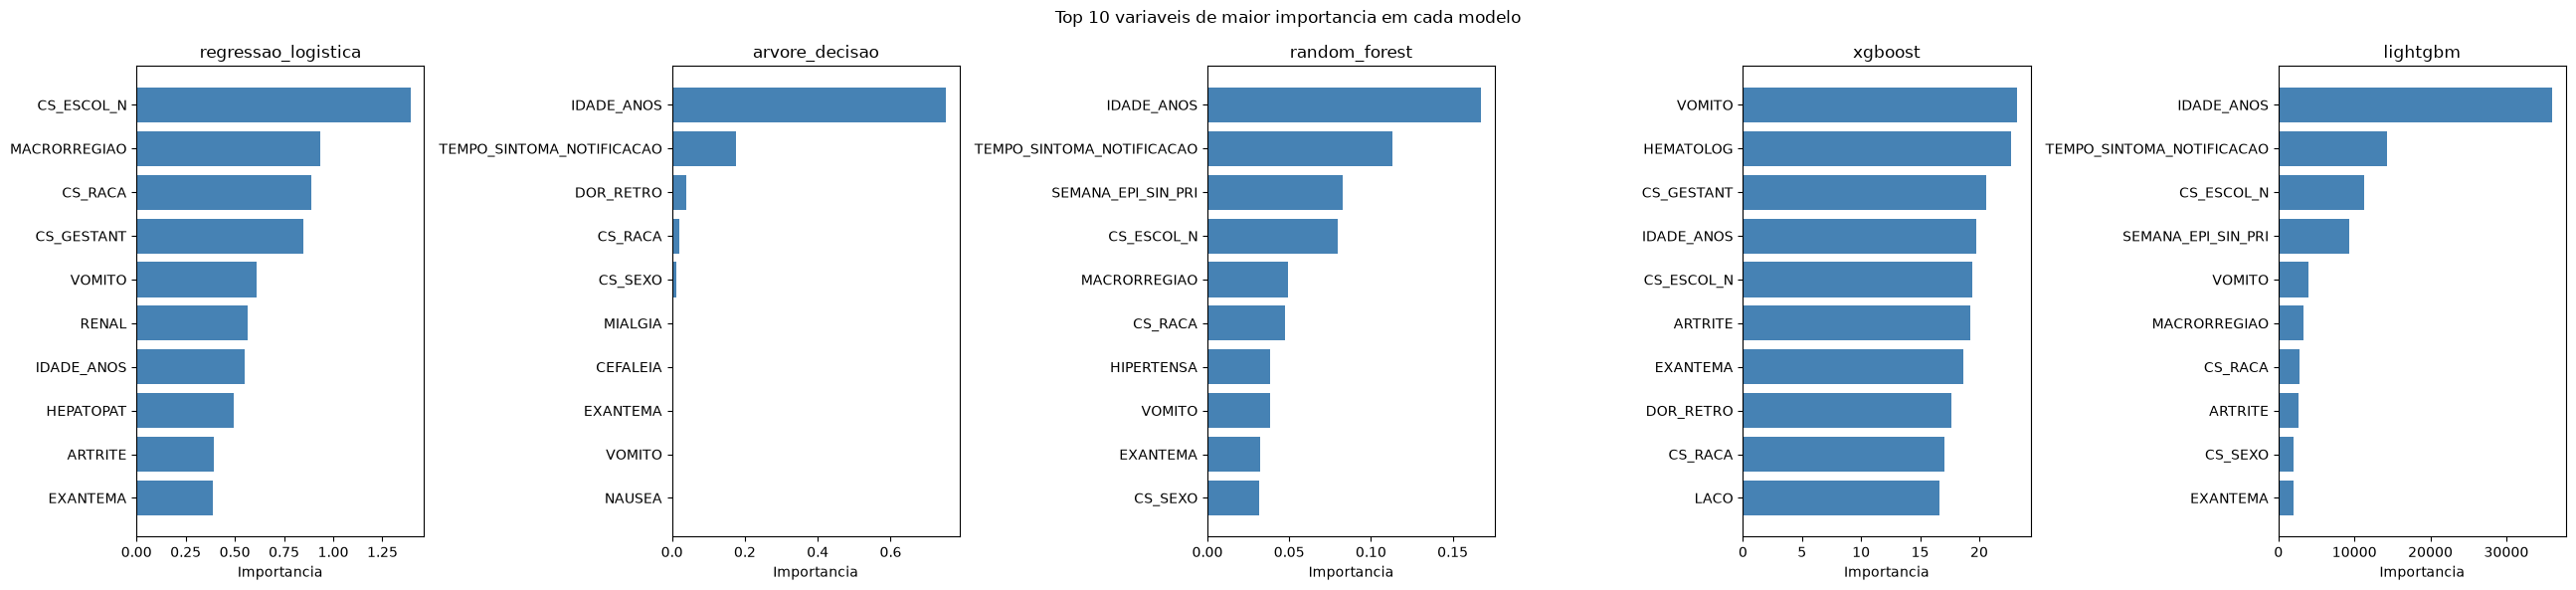

In [12]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(26, 6))

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    top10_algoritmo = tabelas_ranqueadas_por_algoritmo[algoritmo].head(NUMERO_VARIAVEIS_EM_DESTAQUE).iloc[::-1]
    eixo_atual.barh(top10_algoritmo["variavel"], top10_algoritmo["importancia"], color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Importancia")

figura.suptitle("Top 10 variaveis de maior importancia em cada modelo")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "top10_variaveis_por_modelo.png", dpi=150)
plt.show()

## Tabela consolidada entre os cinco modelos

Converte a importancia bruta de cada algoritmo em rank, de 1, a mais importante, a 29, a menos importante, usando rank medio para desempatar variaveis de importancia exatamente igual.
Calcula o rank medio entre os cinco modelos para cada variavel, e ordena a tabela final por esse rank medio, da variavel mais importante em media a menos importante em media.
A tabela e salva em `analysis/results_importancia/ranking_consolidado_5_modelos.csv`.

In [13]:
tabela_rank_por_algoritmo = tabela_importancia_bruta.rank(ascending=False, method="average")
tabela_rank_por_algoritmo = tabela_rank_por_algoritmo.rename(
    columns={algoritmo: f"rank_{algoritmo}" for algoritmo in ALGORITMOS}
)
tabela_rank_por_algoritmo["rank_medio"] = tabela_rank_por_algoritmo.mean(axis=1)

tabela_rank_consolidada = (
    tabela_rank_por_algoritmo.rename_axis("variavel")
    .reset_index()
    .sort_values("rank_medio")
    .reset_index(drop=True)
)
tabela_rank_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "ranking_consolidado_5_modelos.csv", index=False
)
tabela_rank_consolidada

,variavel,rank_regressao_logistica,rank_arvore_decisao,rank_random_forest,rank_xgboost,rank_lightgbm,rank_medio
0,IDADE_ANOS,7.0,1.0,1.0,4.0,1.0,2.8
1,CS_RACA,3.0,4.0,6.0,9.0,7.0,5.8
2,CS_ESCOL_N,1.0,17.5,4.0,5.0,3.0,6.1
3,VOMITO,5.0,17.5,8.0,1.0,5.0,7.3
4,TEMPO_SINTOMA_NOTIFICACAO,17.0,2.0,2.0,14.0,2.0,7.4
5,MACRORREGIAO,2.0,17.5,5.0,11.0,6.0,8.3
6,CS_GESTANT,4.0,17.5,12.0,3.0,11.0,9.5
7,EXANTEMA,10.0,17.5,9.0,7.0,10.0,10.7
8,DOR_RETRO,15.0,3.0,19.0,8.0,12.0,11.4
9,ARTRITE,9.0,17.5,17.0,6.0,8.0,11.5


## Concordancia entre os rankings dos cinco modelos

Calcula a correlacao de Spearman entre as cinco colunas de importancia bruta, o que equivale a correlacionar os rankings das 29 variaveis entre cada par de modelos, numa matriz 5 por 5.
Uma correlacao proxima de 1 indica que dois modelos ordenam as 29 variaveis de forma quase identica, enquanto uma correlacao proxima de 0 indica rankings praticamente independentes entre si.
A matriz e salva em `analysis/results_importancia/concordancia_spearman_entre_modelos.csv`.

In [14]:
matriz_spearman = tabela_importancia_bruta.corr(method="spearman")

matriz_spearman.rename_axis("algoritmo").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "concordancia_spearman_entre_modelos.csv", index=False
)
matriz_spearman

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
regressao_logistica,1.000000,0.150012,0.411330,0.440887,0.576355
arvore_decisao,0.150012,1.000000,0.417863,0.274585,0.493056
random_forest,0.411330,0.417863,1.000000,0.248276,0.752217
xgboost,0.440887,0.274585,0.248276,1.000000,0.562069
lightgbm,0.576355,0.493056,0.752217,0.562069,1.000000


Gera um heatmap da matriz de concordancia de Spearman entre os cinco modelos, com o valor de cada par anotado diretamente sobre a celula correspondente.
O grafico e salvo em `analysis/plots/importancia/heatmap_concordancia_spearman.png`.

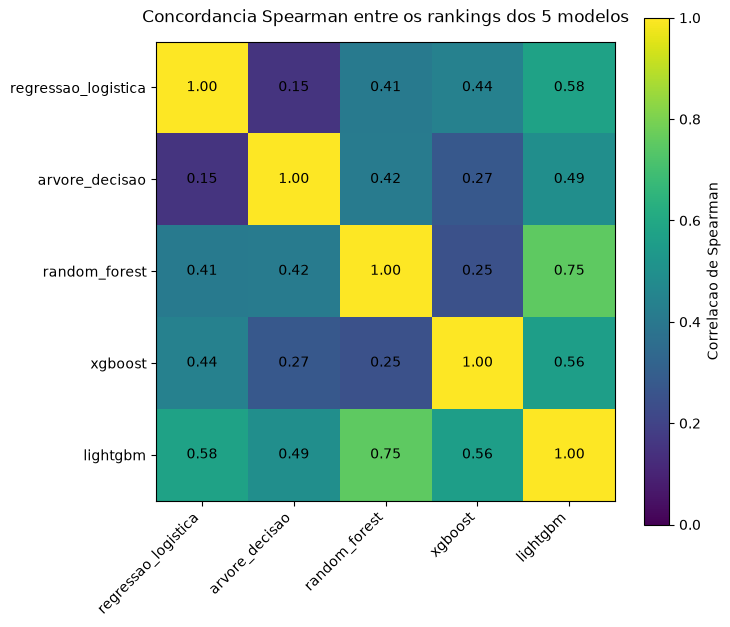

In [15]:
figura, eixo = plt.subplots(figsize=(7.5, 6.5))
mapa_cores = eixo.imshow(matriz_spearman, cmap="viridis", vmin=0, vmax=1)

eixo.set_xticks(range(len(ALGORITMOS)))
eixo.set_xticklabels(ALGORITMOS, rotation=45, ha="right")
eixo.set_yticks(range(len(ALGORITMOS)))
eixo.set_yticklabels(ALGORITMOS)

for linha in range(len(ALGORITMOS)):
    for coluna in range(len(ALGORITMOS)):
        eixo.text(
            coluna, linha, f"{matriz_spearman.iloc[linha, coluna]:.2f}", ha="center", va="center", color="black"
        )

eixo.set_title("Concordancia Spearman entre os rankings dos 5 modelos", pad=14)
figura.colorbar(mapa_cores, ax=eixo, label="Correlacao de Spearman")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "heatmap_concordancia_spearman.png", dpi=150)
plt.show()

## Razao de chances por categoria na Regressao Logistica

A importancia agregada por variavel, usada nas secoes anteriores, soma os valores absolutos dos coeficientes de todas as categorias de uma mesma variavel, o que e adequado para comparar a Regressao Logistica aos demais modelos, mas descarta tanto o sinal quanto a magnitude isolada de cada categoria.
Esta secao recupera, para cada uma das 26 variaveis categoricas, o coeficiente e a razao de chances, `exp(coeficiente)`, de cada categoria individualmente, o nivel de detalhe clinicamente mais interpretavel para esse modelo.
Uma razao de chances acima de 1 indica que a categoria, isolada, esta associada a uma chance maior de obito em relacao ao restante do modelo ajustado, e uma razao de chances abaixo de 1 indica o efeito inverso.
A tabela e salva em `analysis/results_importancia/razao_de_chances_por_categoria_regressao_logistica.csv`.

In [16]:
nomes_colunas_codificadas_regressao_logistica = preprocessador_regressao_logistica.get_feature_names_out()

linhas_razao_de_chances = []
for nome_coluna_codificada, coeficiente in zip(
    nomes_colunas_codificadas_regressao_logistica, coeficientes_regressao_logistica
):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador != "categoricas":
        continue

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            categoria = nome_apos_prefixo[len(variavel_categorica) + 1 :]
            linhas_razao_de_chances.append(
                {
                    "variavel": variavel_categorica,
                    "categoria": categoria,
                    "coeficiente": coeficiente,
                    "razao_de_chances": np.exp(coeficiente),
                }
            )
            break

tabela_razao_de_chances_categorica = pd.DataFrame(linhas_razao_de_chances)
tabela_razao_de_chances_categorica["categoria"] = tabela_razao_de_chances_categorica["categoria"].apply(
    lambda valor: "ausente_sem_imputacao" if valor is None or valor == "None" else valor
)
tabela_razao_de_chances_categorica = tabela_razao_de_chances_categorica.sort_values(
    "razao_de_chances", ascending=False
).reset_index(drop=True)

tabela_razao_de_chances_categorica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "razao_de_chances_por_categoria_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_categorica.head(10)

,variavel,categoria,coeficiente,razao_de_chances
0,VOMITO,1,0.305002,1.356627
1,MACRORREGIAO,Centro-Oeste,0.292706,1.340049
2,RENAL,1,0.282251,1.326112
3,CS_RACA,4,0.267325,1.306465
4,HEPATOPAT,1,0.246086,1.279009
5,CS_ESCOL_N,4,0.217806,1.243346
6,ARTRITE,2,0.196298,1.216889
7,CS_ESCOL_N,6,0.193473,1.213457
8,EXANTEMA,2,0.192327,1.212067
9,LEUCOPENIA,1,0.192308,1.212044


A categoria `ausente_sem_imputacao` de `CS_ESCOL_N`, visivel na tabela quando a variavel aparece, corresponde a 907 dos 7171 casos de treino cujo nivel de escolaridade nao foi informado.
Esses casos nao foram convertidos para a categoria constante `ausente`, usada para todas as demais variaveis categoricas, porque o valor ausente nessa coluna especifica e representado no dado tratado pelo objeto `None`, que o `SimpleImputer` de `scikit-learn` nao reconhece como ausente numa coluna de tipo texto.
Essa e uma particularidade pontual deste pipeline ja treinado, e afeta apenas o rotulo dessa categoria especifica na tabela de razao de chances, sem nenhum efeito sobre a importancia agregada de `CS_ESCOL_N` nas secoes anteriores, nem sobre nenhuma outra das 29 variaveis.

In [17]:
numero_casos_categoria_ausente_sem_imputacao = int(X_train["CS_ESCOL_N"].isna().sum())
numero_casos_categoria_ausente_sem_imputacao, len(X_train)

(907, 7171)

Como os tres preditores numericos, `IDADE_ANOS`, `SEMANA_EPI_SIN_PRI` e `TEMPO_SINTOMA_NOTIFICACAO`, foram padronizados antes do ajuste da Regressao Logistica, cada um tem um unico coeficiente, e a razao de chances correspondente e por aumento de um desvio padrao, nao por uma unidade bruta da variavel, como um ano de idade.
Esta tabela complementar reune o coeficiente e a razao de chances por desvio padrao desses tres preditores, e e salva em `analysis/results_importancia/coeficientes_variaveis_numericas_regressao_logistica.csv`.

In [18]:
linhas_razao_de_chances_numericas = []
for variavel_numerica in COLUNAS_NUMERICAS:
    indice_coluna = list(nomes_colunas_codificadas_regressao_logistica).index(f"numericas__{variavel_numerica}")
    coeficiente = coeficientes_regressao_logistica[indice_coluna]
    linhas_razao_de_chances_numericas.append(
        {
            "variavel": variavel_numerica,
            "coeficiente_por_desvio_padrao": coeficiente,
            "razao_de_chances_por_desvio_padrao": np.exp(coeficiente),
        }
    )

tabela_razao_de_chances_numerica = (
    pd.DataFrame(linhas_razao_de_chances_numericas)
    .sort_values("razao_de_chances_por_desvio_padrao", ascending=False)
    .reset_index(drop=True)
)

tabela_razao_de_chances_numerica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "coeficientes_variaveis_numericas_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_numerica

,variavel,coeficiente_por_desvio_padrao,razao_de_chances_por_desvio_padrao
0,IDADE_ANOS,0.549706,1.732744
1,TEMPO_SINTOMA_NOTIFICACAO,0.242771,1.274777
2,SEMANA_EPI_SIN_PRI,0.079381,1.082616


## Sintese dos achados

Idade (`IDADE_ANOS`) e a variavel de maior importancia media entre os cinco modelos, com rank medio de 2,8, seguida por raca ou cor (`CS_RACA`), com rank medio de 5,8, por escolaridade (`CS_ESCOL_N`), com rank medio de 6,1, por vomito (`VOMITO`), com rank medio de 7,3, e por tempo entre inicio dos sintomas e notificacao (`TEMPO_SINTOMA_NOTIFICACAO`), com rank medio de 7,4.
Idade e a variavel de maior importancia isolada em tres dos cinco modelos, Arvore de Decisao, Random Forest e LightGBM, aparece na quarta posicao no XGBoost e na setima na Regressao Logistica, e e a unica variavel presente no top 10 dos cinco modelos ao mesmo tempo.

A nova variavel geografica, `MACRORREGIAO`, com 5 categorias, Norte, Nordeste, Centro-Oeste, Sudeste e Sul, ocupa a sexta posicao no rank medio consolidado, com 8,3, a segunda posicao na Regressao Logistica, a quinta no Random Forest, a sexta no LightGBM, e a decima primeira no XGBoost, ficando empatada em importancia zero com outras 23 variaveis na Arvore de Decisao.
Essa posicao e bem mais moderada do que a da antiga unidade federada de residencia, `SG_UF`, que antes desta troca de variavel ocupava a primeira posicao na Regressao Logistica por uma margem grande sobre as demais variaveis, com importancia bruta de 3,48 contra 1,44 da segunda colocada naquela rodada.
Com apenas 5 categorias, bem menos do que as 27 de `SG_UF`, e com uma posicao relativamente proxima entre os quatro modelos que nao sao a Arvore de Decisao, segunda, quinta, sexta e decima primeira, `MACRORREGIAO` sugere que a ressalva anterior sobre cardinalidade inflando artificialmente a importancia da variavel geografica na Regressao Logistica nao se aplica mais com a mesma intensidade.

`CS_ESCOL_N` e agora a variavel categorica de maior cardinalidade do conjunto de preditores, com 12 categorias, incluindo a categoria de valor ausente, e e tambem a variavel de maior importancia bruta isolada na Regressao Logistica, 1,39, acima inclusive de idade.
Essa primeira posicao na Regressao Logistica e parcialmente consistente com a mesma ressalva de cardinalidade descrita para `SG_UF` na rodada anterior, ja que a soma dos valores absolutos de 12 coeficientes de categoria favorece mecanicamente essa variavel frente a um preditor numerico como idade, que contribui com um unico coeficiente para essa soma.
Essa ressalva, porem, e mais branda para `CS_ESCOL_N` do que foi para `SG_UF`, porque os quatro modelos restantes tambem colocam `CS_ESCOL_N` entre as cinco variaveis mais importantes, exceto a Arvore de Decisao: terceira no LightGBM, quarta no Random Forest e quinta no XGBoost, o que indica que boa parte da importancia atribuida a essa variavel tambem e corroborada por modelos que nao sofrem desse efeito mecanico de soma por categoria.

A Arvore de Decisao final selecionada pela busca de hiperparametros tem profundidade maxima 3 e apenas 8 folhas, o que limita a 5 o numero de variaveis usadas em pelo menos uma divisao, `IDADE_ANOS`, `TEMPO_SINTOMA_NOTIFICACAO`, `DOR_RETRO`, `CS_RACA` e `CS_SEXO`, deixando as demais 24 variaveis, incluindo `MACRORREGIAO`, com importancia de Gini exatamente igual a zero.
Essa concentracao extrema em poucas variaveis torna o ranking da Arvore de Decisao isolada pouco informativo para qualquer variavel fora dessas 5, e explica por que ela e o modelo mais discordante dos demais na analise de concordancia a seguir.

O XGBoost se destaca neste ajuste por atribuir ganho elevado a duas variaveis com importancia bem mais baixa nos demais modelos: doenca hematologica previa (`HEMATOLOG`), segunda colocada no XGBoost mas apenas vigesima quarta no rank medio consolidado, com importancia tambem muito baixa no Random Forest e a mais baixa de todas no LightGBM, e o resultado do teste do laco (`LACO`), decimo colocado no XGBoost mas vigesimo segundo no rank medio consolidado, com a importancia mais baixa de todas na Regressao Logistica e tambem muito baixa no Random Forest.
Essa discordancia pode refletir uma caracteristica do ganho de arvores de boosting: ele soma a melhoria de impureza de cada divisao em que a variavel participa, mesmo quando sao poucas divisoes sobre um subgrupo pequeno de casos, enquanto a importancia de Gini do Random Forest pondera essa melhoria pela fracao de observacoes que passa por cada divisao em cada arvore do ensemble.

A correlacao de Spearman entre os rankings dos cinco modelos varia de 0,150, entre Regressao Logistica e Arvore de Decisao, a 0,752, entre Random Forest e LightGBM, com media de 0,433 entre os dez pares possiveis de modelos.
Essa concordancia media e bem mais baixa do que a observada na rodada anterior com `SG_UF`, e e consistente com a profundidade muito baixa da Arvore de Decisao final, que empata em zero a maioria das variaveis, e com a discordancia especifica do XGBoost em `HEMATOLOG` e `LACO` descrita acima.
A segunda correlacao mais baixa entre os dez pares, 0,248, e justamente entre Random Forest e XGBoost, dois modelos de arvore que nesta rodada discordam mais entre si do que a Regressao Logistica discorda da maioria dos outros quatro modelos.
Random Forest e LightGBM formam o unico par de modelos com correlacao de Spearman acima de 0,7, o que indica que, apesar da baixa concordancia media, os dois ensembles de arvore de maior porte ainda ordenam as 29 variaveis de forma bastante parecida entre si.

Na tabela de razao de chances por categoria da Regressao Logistica, a categoria de maior razao de chances isolada e a categoria que indica presenca do sintoma em `VOMITO`, com razao de chances de 1,36, seguida pela categoria Centro-Oeste de `MACRORREGIAO`, com razao de chances de 1,34.
Entre as cinco categorias de `MACRORREGIAO`, Centro-Oeste e Sudeste tem razao de chances acima de 1, 1,34 e 1,19 respectivamente, Nordeste e Sul ficam muito proximas de 1, 0,98 e 0,96, e Norte tem a menor razao de chances entre as cinco, 0,67, a segunda menor de toda a tabela de categorias, atras apenas da categoria 9 de `CS_RACA`, com razao de chances de 0,64.
Os tres preditores numericos tem razao de chances por desvio padrao de 1,73 para idade, 1,27 para o tempo entre inicio dos sintomas e notificacao, e 1,08 para a semana epidemiologica, sempre por um aumento de um desvio padrao, e nao por uma unidade bruta da variavel, ja que as tres foram padronizadas antes do ajuste da Regressao Logistica.
Os codigos de categoria de `CS_RACA` e das demais variaveis categoricas codificadas numericamente seguem a codificacao original do SINAN e nao sao decodificados neste notebook, enquanto as categorias de `MACRORREGIAO` ja chegam nomeadas pelo pipeline de dados.

Este notebook se limita a produzir e descrever estes resultados quantitativos internos ao estudo, sem comparacao com a literatura cientifica sobre fatores de risco de obito por chikungunya, etapa que fica para um momento posterior fora deste notebook.